# Notebook 6 · Question 7: the 2025 forecast and the dashboard
Runs `src/forecast_next.py` (scores every municipality-year with the locked pipeline and forecasts the 2025 audit from 2024 figures), then
uses the dashboard's own prediction code (`app/core.py`) on the demonstration files. The dashboard itself is launched with
`streamlit run app/app.py`; the screenshots below are captures of the current app.

In [1]:
import sys, json, logging, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:.3f}".format)
RESULTS, FIGS = ROOT / "results", ROOT / "reports" / "figures"
show = lambda name, width=800: display(Image(filename=str(FIGS / name), width=width))

In [2]:
import forecast_next
forecast_next.main()
scores = pd.read_csv(RESULTS / "municipality_scores.csv")
fc = scores[scores.split == "forecast"]
print(f"2025 forecast: {len(fc)} municipalities, {(fc.predicted_outcome == 'at_risk').sum()} flagged at risk, "
      f"{(fc.risk_probability >= 0.8).sum()} at 80% or more")
fc.sort_values("risk_probability", ascending=False)[["Name", "demarcation.code", "province", "category",
                                                     "prior_audit_opinion_raw", "risk_probability"]].head(10)

    keywords ['cash', 'cash equivalents'] matched items: ['Cash and cash equivalents']


    keywords ['property rates'] matched items: ['Property rates']


    keywords ['service charges'] matched items: ['Service charges - Electricity', 'Service charges - Water', 'Service charges - Waste Water Management', 'Service charges - Waste Management']


    keywords ['debt impairment'] matched items: ['Debt impairment']
    keywords ['total by income source'] matched items: ['Total By Income Source']
    keywords ['irregular'] matched items: ['Irregular Expenditure']


Rebuilt features matched for 1434/1434 rows; worst relative difference = 2.43e-16


Test-year probabilities match Q5 for 240 municipalities

Rows by split: {'fitted': 1194, 'forecast': 245, 'test': 240}
Forecast for the 2025 audit: 245 municipalities, 106 flagged at risk (mean risk 44.6%)
Unknown provinces: []


2025 forecast: 245 municipalities, 106 flagged at risk, 102 at 80% or more


,Name,demarcation.code,province,category,prior_audit_opinion_raw,risk_probability
1442,Ratlou,NW381,North West,Local,disclaimer,0.888
594,Maluti-a-Phofung,FS194,Free State,Local,outstanding,0.866
735,Msunduzi,KZN225,KwaZulu-Natal,Local,outstanding,0.865
1304,Renosterberg,NC075,Northern Cape,Local,qualified,0.864
1498,City of Matlosana,NW403,North West,Local,qualified,0.864
1460,Ditsobotla,NW384,North West,Local,disclaimer,0.864
568,Matjhabeng,FS184,Free State,Local,outstanding,0.861
660,Merafong City,GT484,Gauteng,Local,qualified,0.861
6,Buffalo City,BUF,Eastern Cape,Metro,qualified,0.858
1512,J B Marks,NW405,North West,Local,qualified,0.857


## 7.2–7.4 The dashboard's prediction code on the demonstration cases (three valid, one invalid)

In [3]:
sys.path.insert(0, str(ROOT / "app"))
import core
for f in ["valid_cases.csv", "invalid_case.csv"]:
    raw = pd.read_csv(ROOT / "app" / "samples" / f, dtype=str)
    clean, errors, warns, valid = core.validate(raw)
    print(f"--- {f}: {int(valid.sum())} of {len(raw)} rows valid")
    for e in errors: print("  ERROR:", e)
    for w in warns: print("  warning:", w)
    if valid.any():
        prob, label = core.predict(clean[valid])
        display(pd.DataFrame({"municipality": clean[valid]["Name"], "risk": prob.round(3), "prediction": label}))

--- valid_cases.csv: 3 of 3 rows valid


,municipality,risk,prediction
0,Masilonyana,0.899,at_risk
1,eThekwini,0.092,not_at_risk
2,Tsantsabane,0.772,at_risk


--- invalid_case.csv: 0 of 1 rows valid
  ERROR: Invalid example: 'four hundred million' is not a number for Total revenue.
  ERROR: Invalid example: Total expenditure must be greater than zero (in rand).
  ERROR: Invalid example: last year's audit outcome 'maybe' is not recognised. Use at_risk / not_at_risk or an AGSA opinion (unqualified, qualified, adverse, disclaimer, outstanding).


In [4]:
row = fc[fc["demarcation.code"] == "GT421"]
prob, label = core.predict(row)
print(f"Emfuleni 2025 forecast: {prob[0]:.1%} ({label[0]})")
for line in core.plain_language(prob[0], label[0], core.explain(row)):
    print(" -", line.replace("<b>", "").replace("</b>", "").replace('<span class="up">', "").replace('<span class="down">', "").replace("</span>", ""))

Emfuleni 2025 forecast: 85.4% (at_risk)
 - The model estimates a 85% chance that this municipality's next audit is poor, so it is flagged as at risk of a poor audit outcome (qualified, adverse, disclaimer or outstanding).
 - Last year's audit outcome (at risk) raises the risk the most — audit results tend to repeat from year to year.
 - Operating surplus / deficit of −R1.43 bn (typical: −R26.3 m) raises the risk.
 - Repairs & maintenance spend of 8.0% (typical: 2.0%) lowers the risk.


## Screenshots of the dashboard (current version)

app_overview_full.png


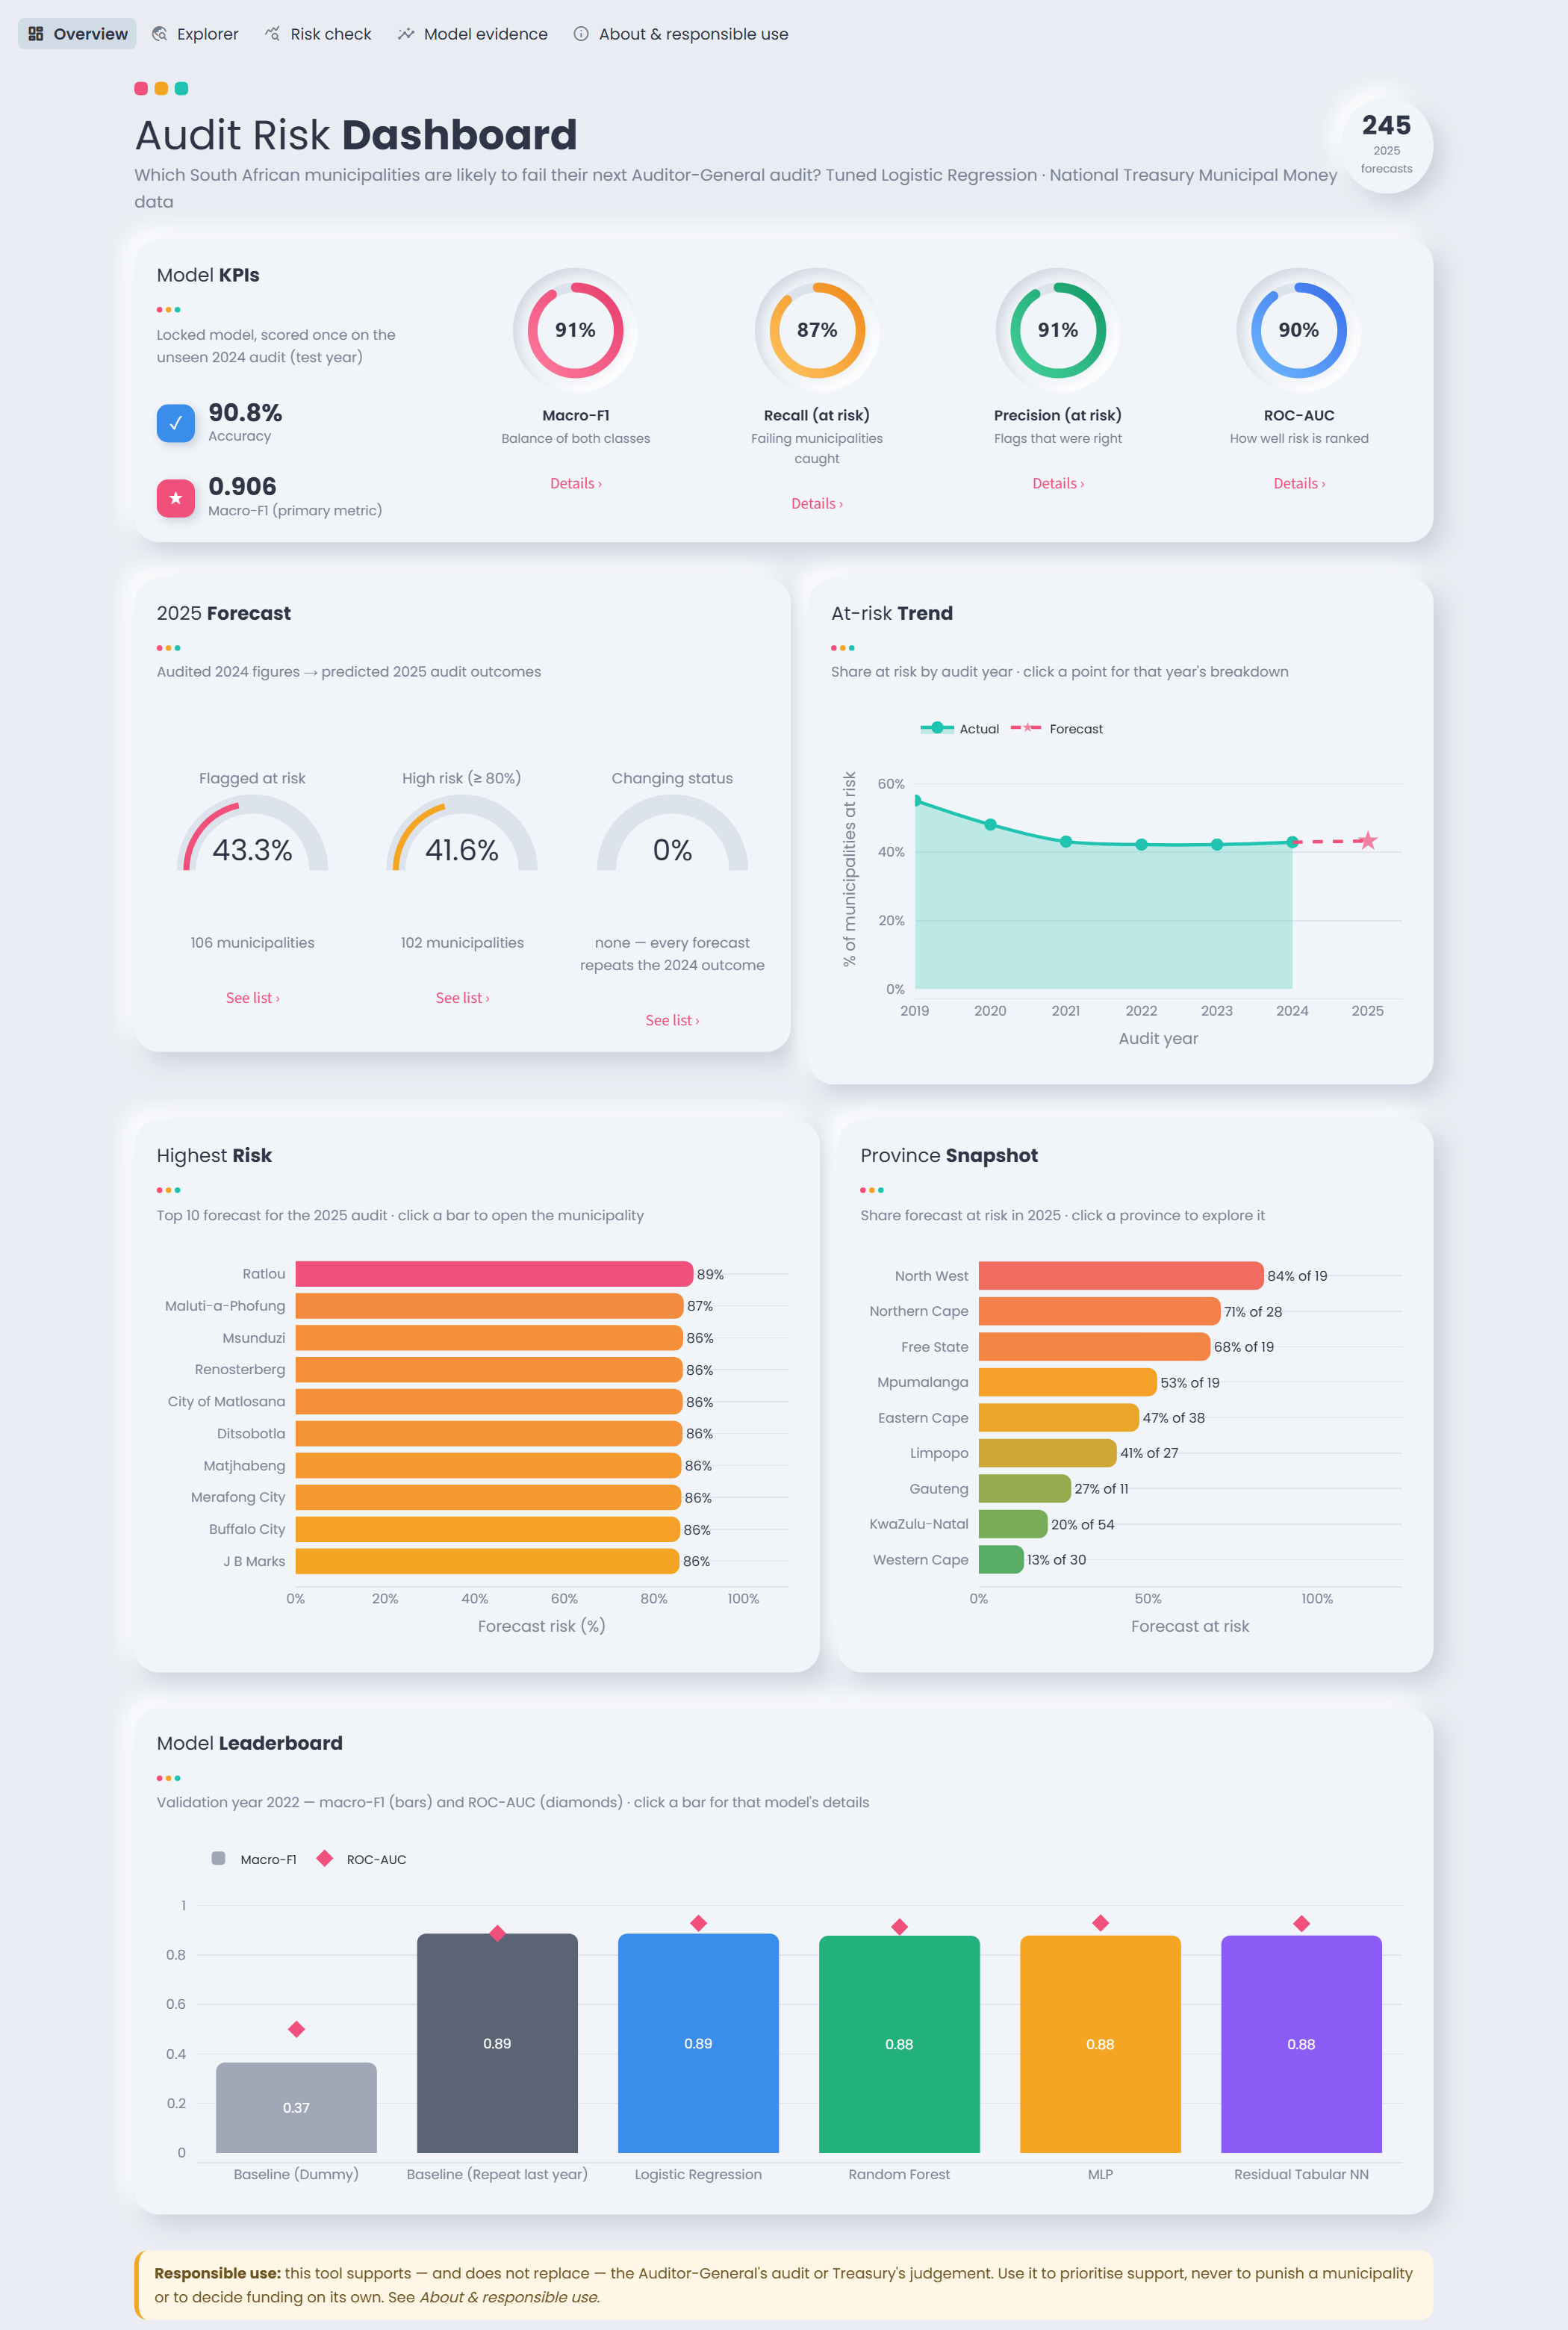

app_risk_check_result.png


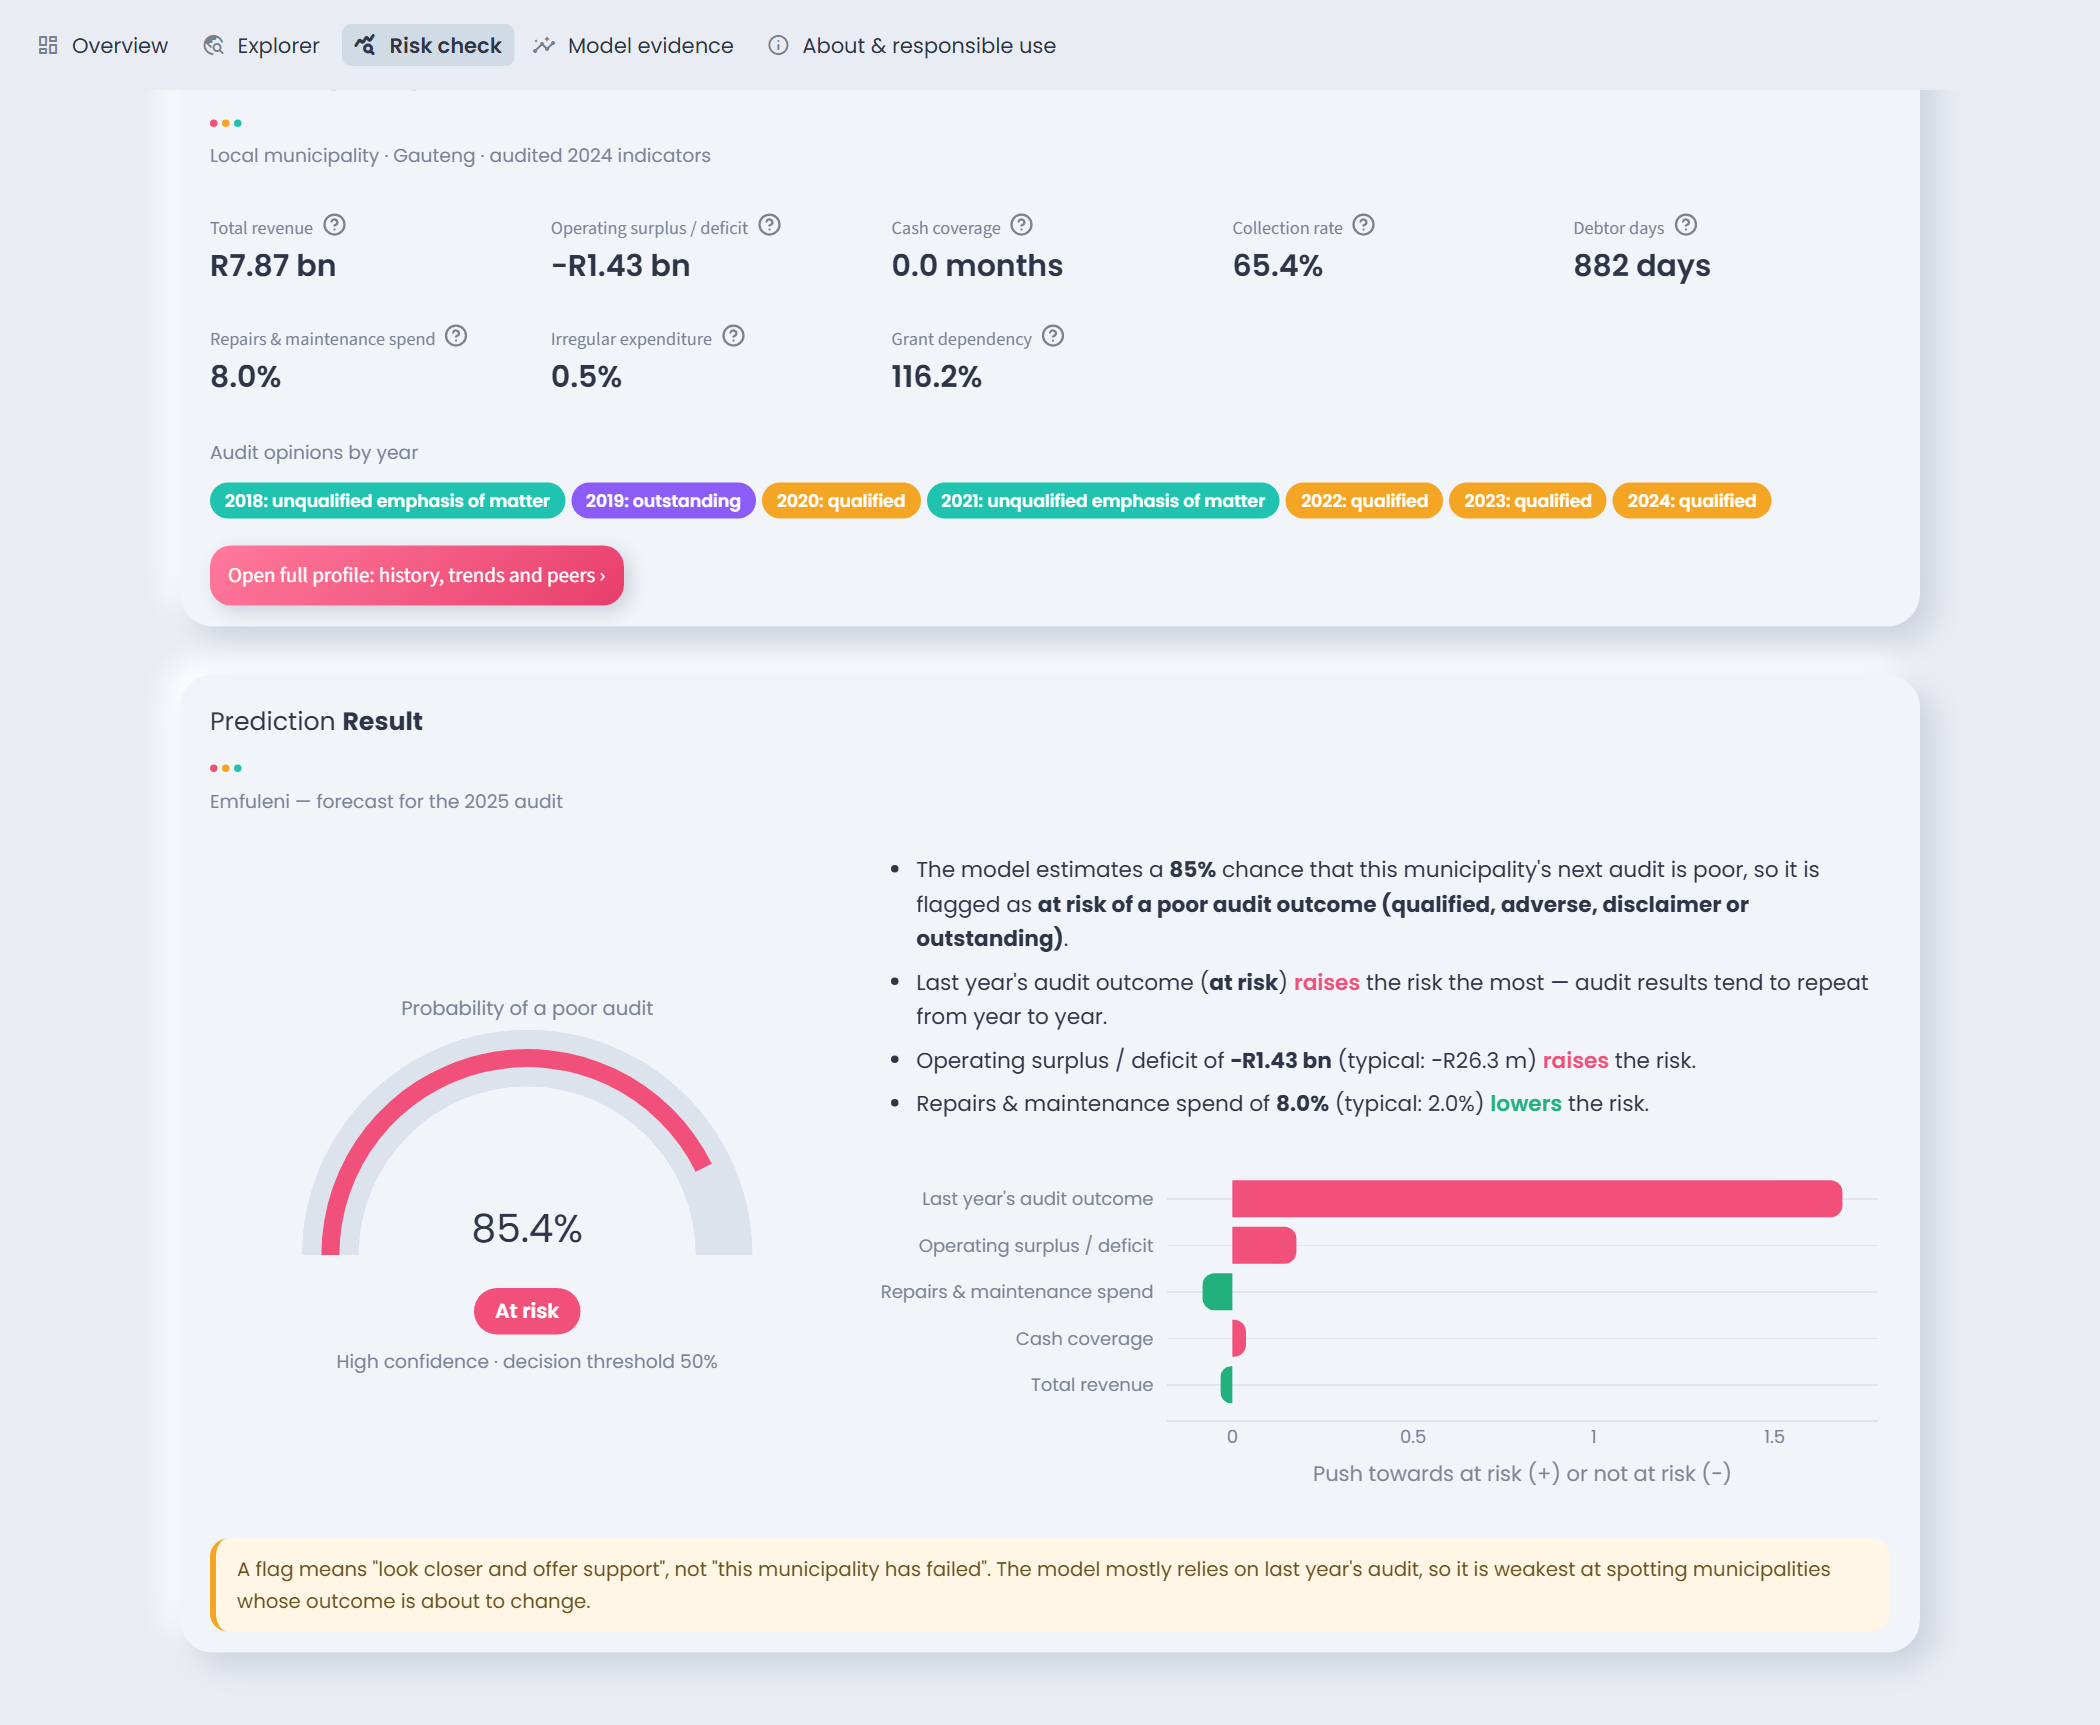

app_invalid_input.png


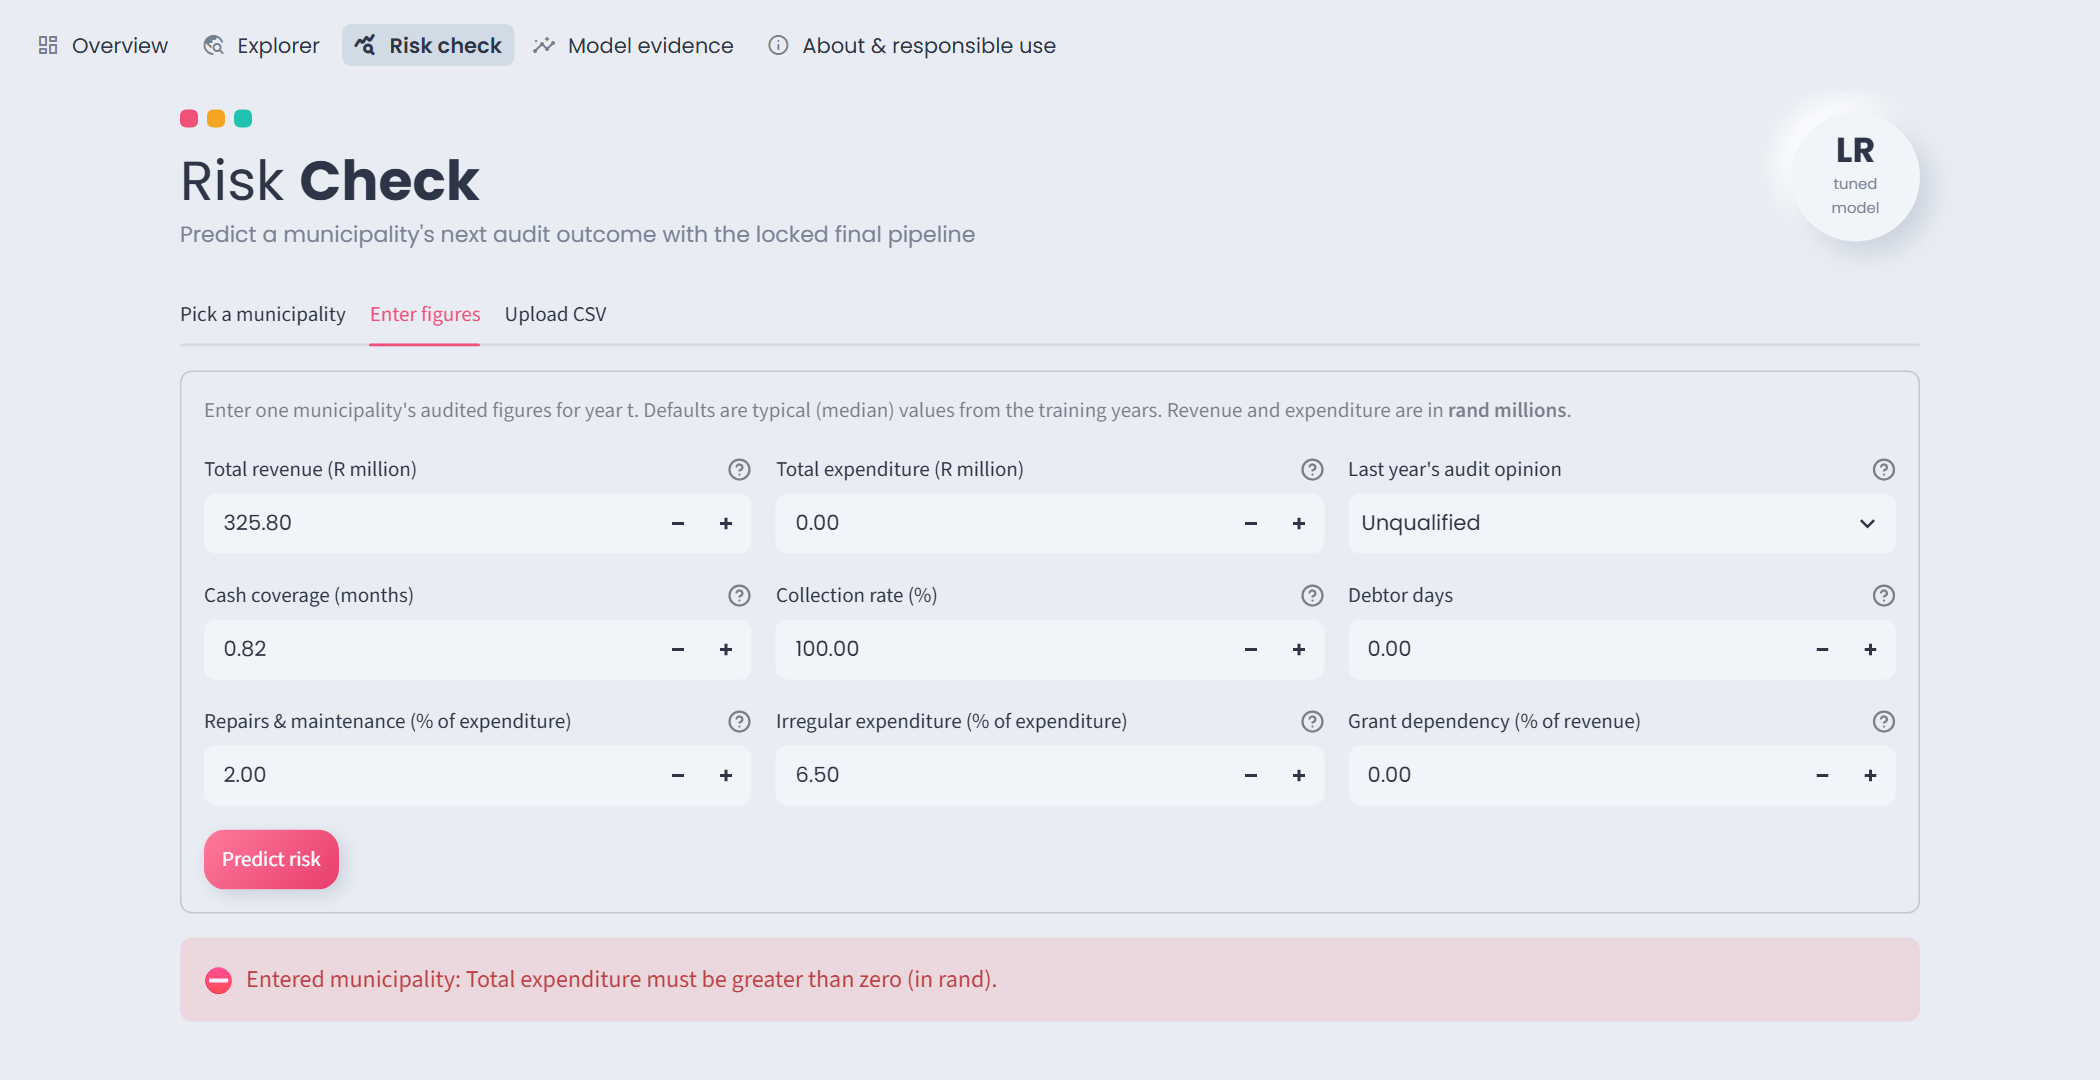

app_profile_top.png


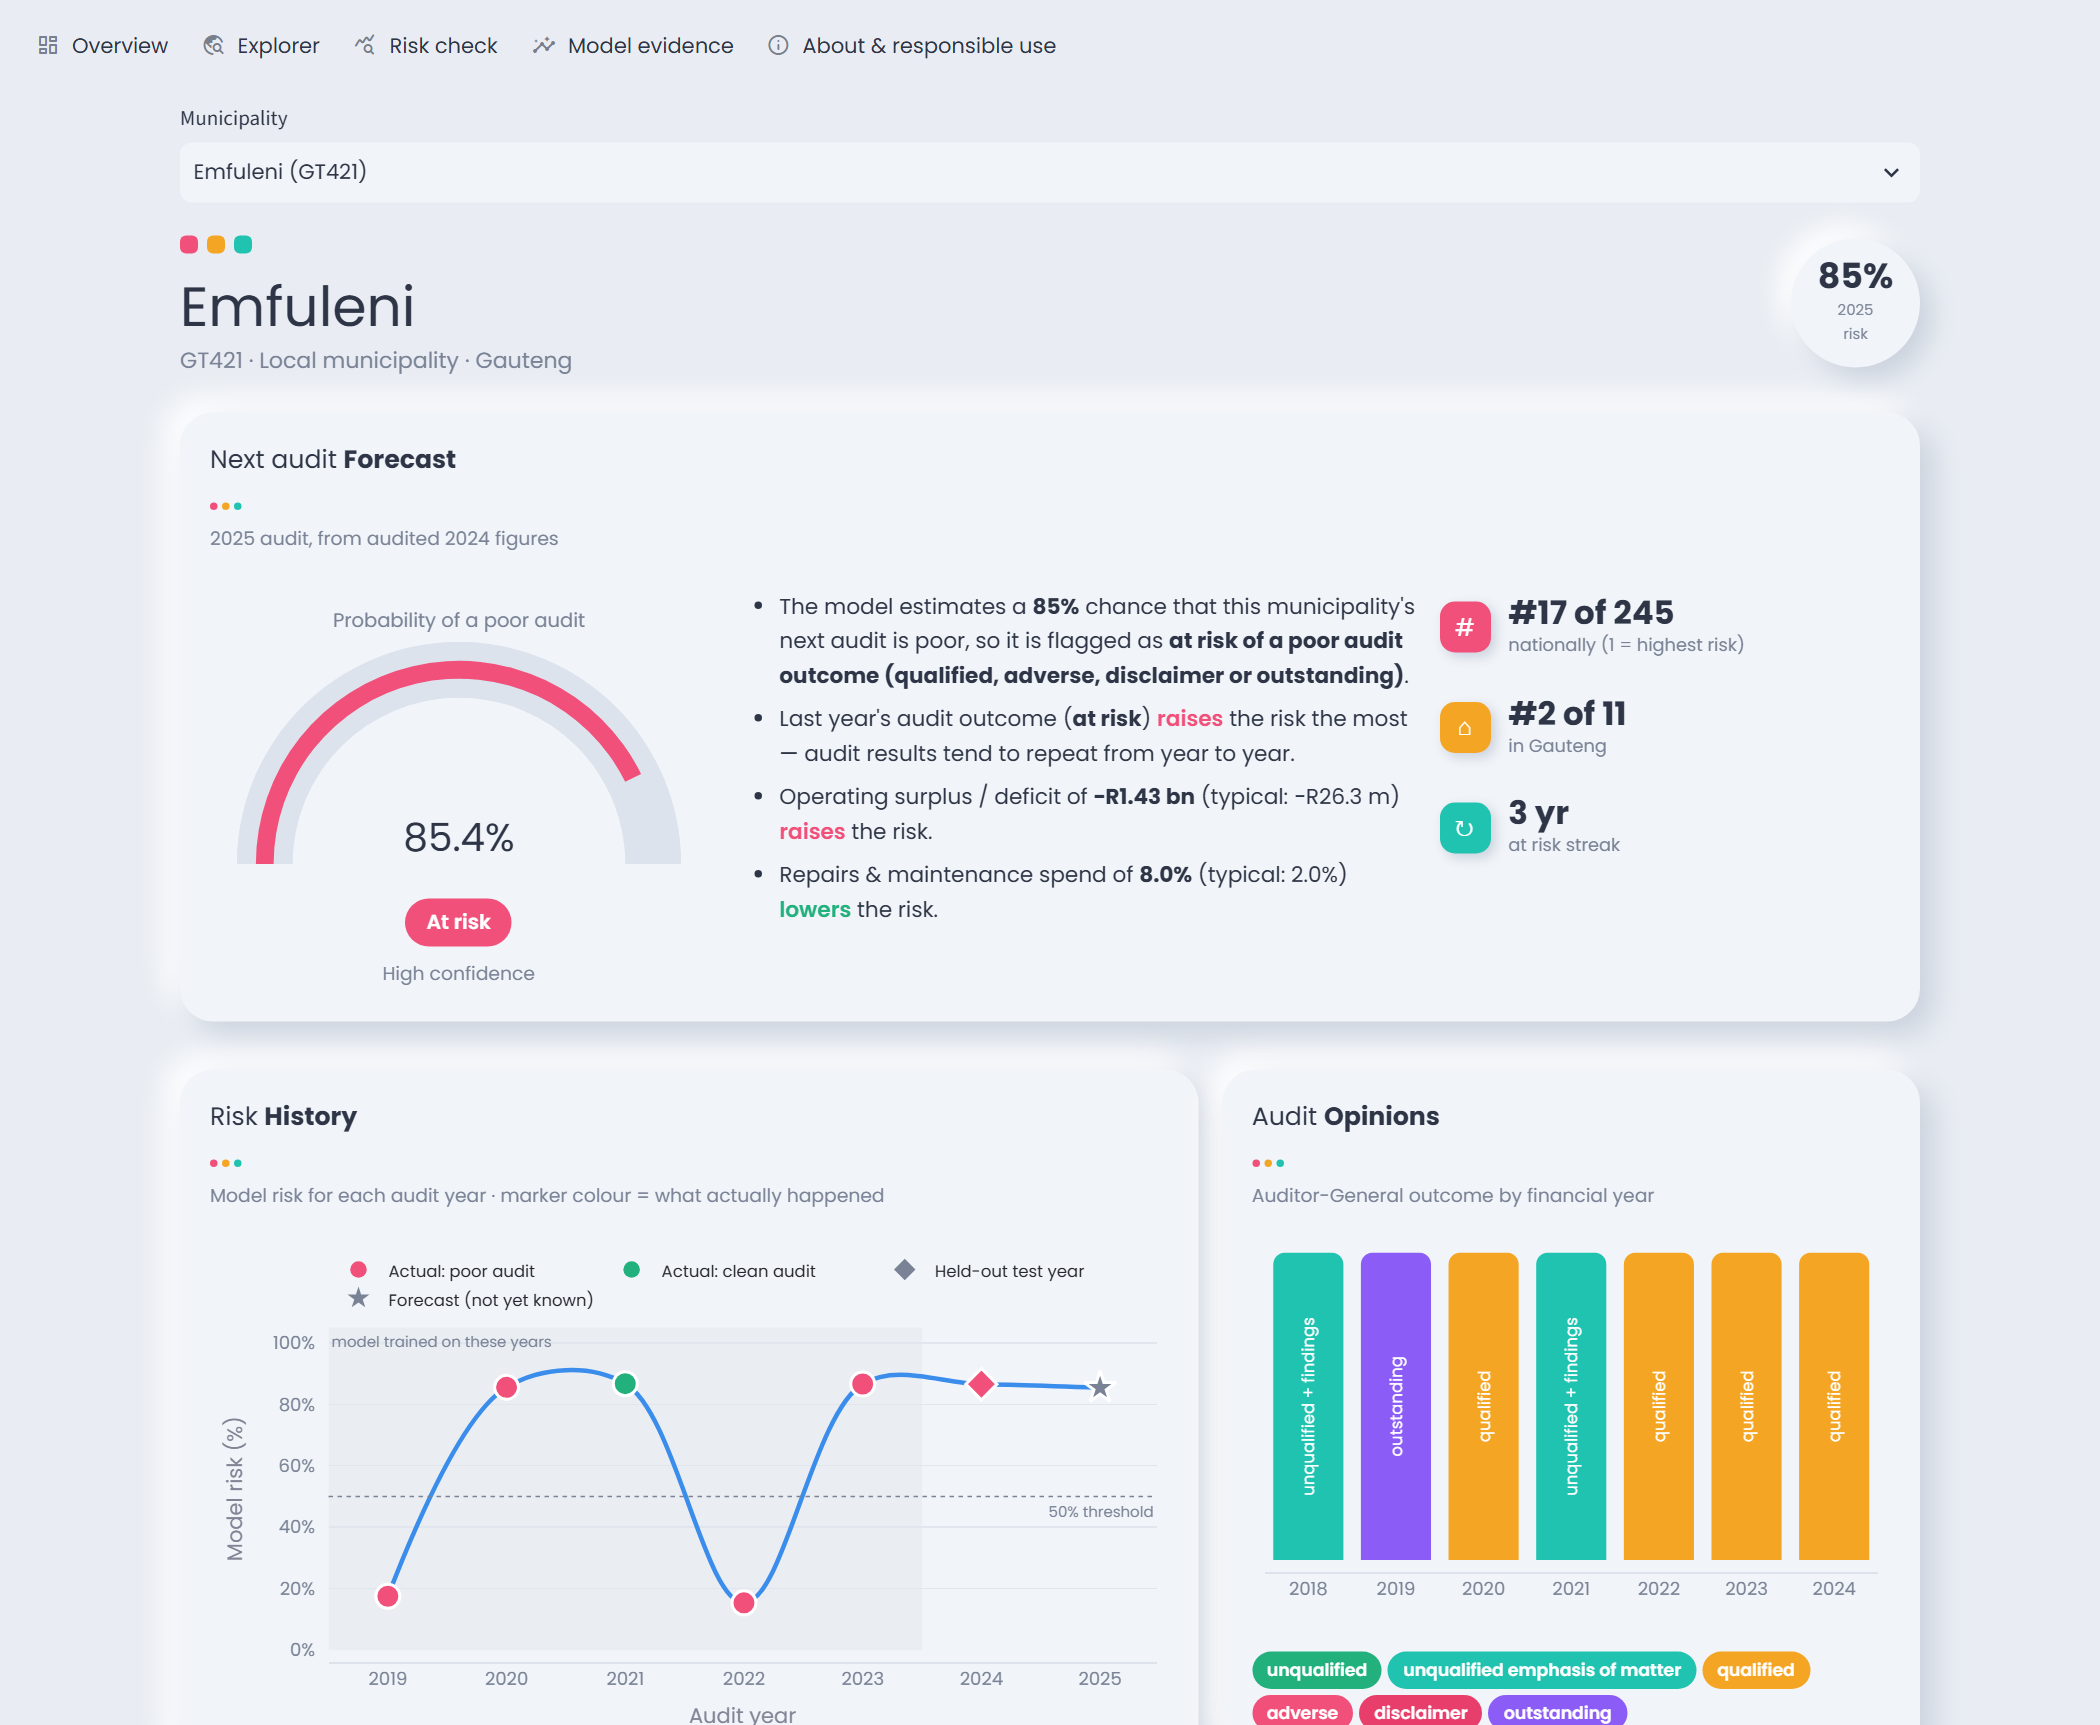

app_explorer.png


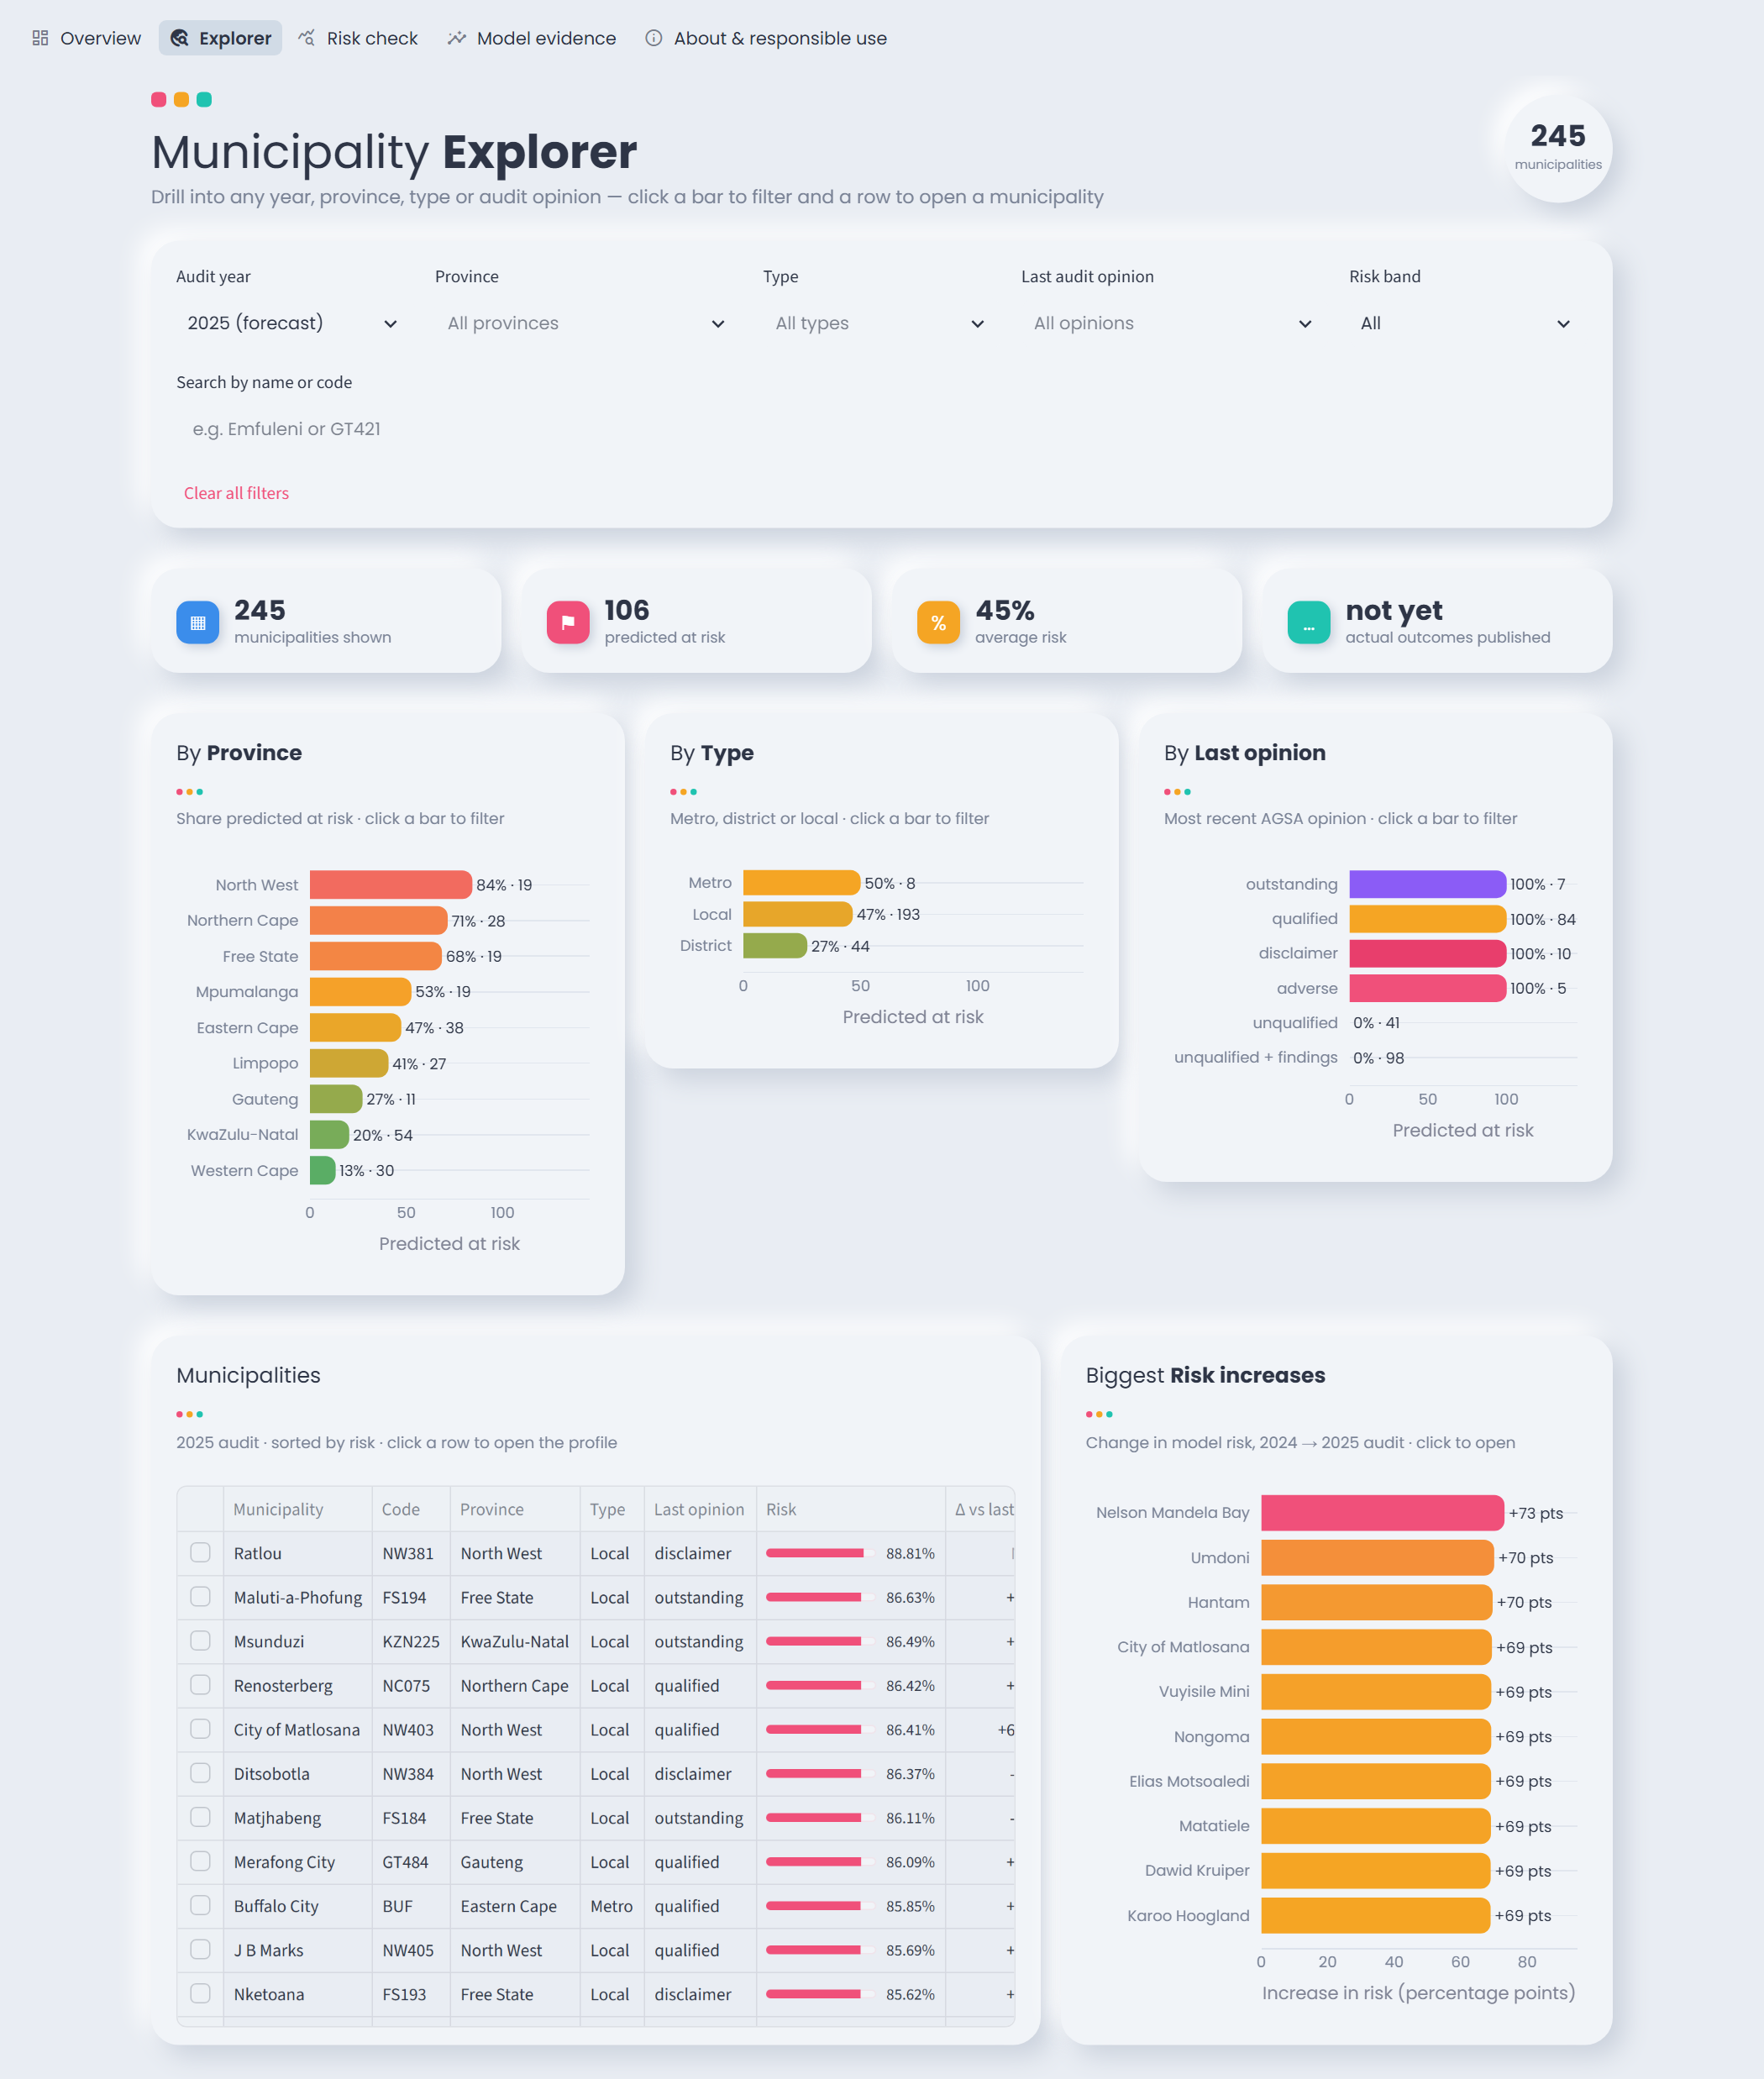

app_dialog_recall.png


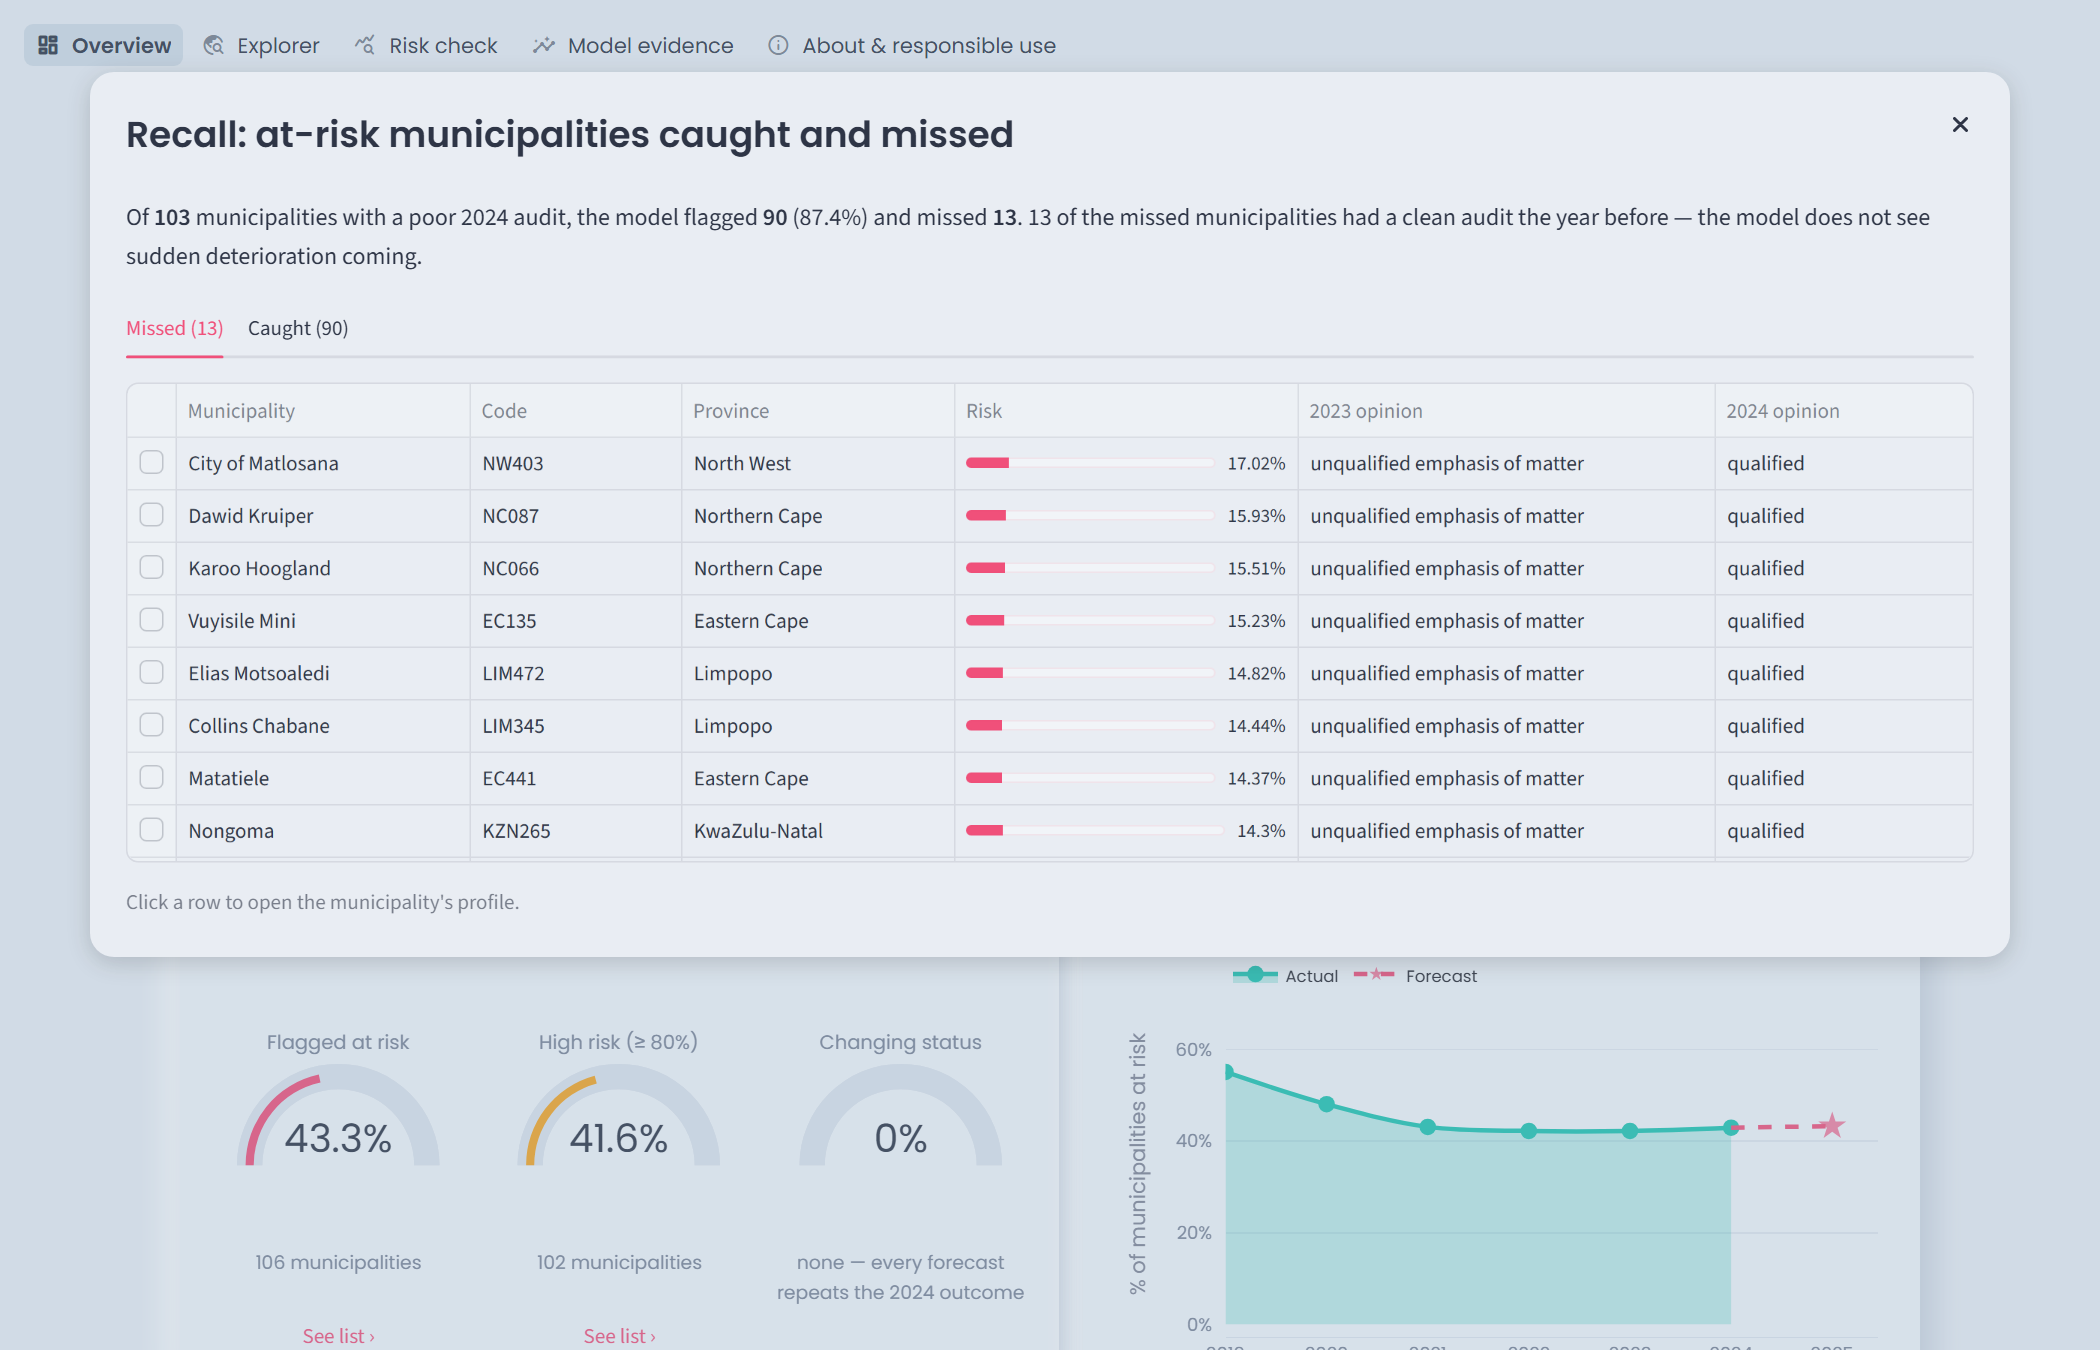

In [5]:
for name in ["app_overview_full.png", "app_risk_check_result.png", "app_invalid_input.png", "app_profile_top.png",
             "app_explorer.png", "app_dialog_recall.png"]:
    print(name); show("app/" + name, 760)